In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm
from torchvision import datasets, transforms
import torch.nn.functional as F

# Modelin işləmə prinsipi
1. MNIST şəkil - giriş məlumatı
2. Flatten 2d şəkli - 1d vektora çeviririk
3. Linear - matris hasil və bias
4. Softmax - hər rəqəm üçün ehtimal hesablanır
5. Proqnoz - ən yüksək qiymətə malik class seçilir

In [3]:
mnist_train = datasets.MNIST(
    root='./data',
    train=True,
    transform=transforms.ToTensor(),
    download=True
)
mnist_train

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [4]:
mnist_test = datasets.MNIST(
    root='./data',
    train=False,
    transform=transforms.ToTensor(),
    download=True
)
mnist_test

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [5]:
mnist_train.data.shape, mnist_test.data.shape

(torch.Size([60000, 28, 28]), torch.Size([10000, 28, 28]))

In [6]:
image, label = mnist_train[3]
image.shape

torch.Size([1, 28, 28])

In [7]:
image = image.reshape([28, 28])
image.shape

torch.Size([28, 28])

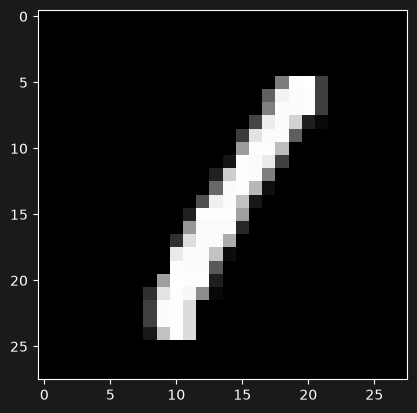

Label: 1


In [8]:
plt.imshow(image, cmap='gray')
plt.show()
print(f'Label: {label}')

In [9]:
train_loader = torch.utils.data.DataLoader(
    dataset=mnist_train,
    batch_size=100,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    dataset=mnist_test,
    batch_size=100,
    shuffle=False
)

In [10]:
data_train_iter = iter(train_loader)
images, labels = next(data_train_iter)
print(images.shape)
print(labels.shape)

torch.Size([100, 1, 28, 28])
torch.Size([100])


In [11]:
x = images.view(-1, 28*28)
print(x.shape)

torch.Size([100, 784])


$$
y_1 = \sum_ix_iw_{i, 1} + b_1
$$

$$
y =  zW + b
$$

In [12]:
W = torch.randn(784, 10) / np.sqrt(784) # Xavier initialization

$$
\sigma = \frac{1}{\sqrt{784}}
$$

[XE VS HE habr](https://habr.com/ru/articles/932852/)

[Xavier in geeksforgeeks](https://www.geeksforgeeks.org/deep-learning/xavier-initialization/)

[XE vs HE medium](https://medium.com/thedeephub/he-and-xavier-weight-initialization-functions-acedc5322ce5)


In [13]:
W.requires_grad = True
b = torch.zeros(10, requires_grad=True)
W, b

(tensor([[-0.0051, -0.0163,  0.0267,  ...,  0.0150,  0.0657, -0.0231],
         [ 0.0541, -0.0042, -0.0199,  ...,  0.0166, -0.0371, -0.0002],
         [-0.0126,  0.0218, -0.0213,  ...,  0.0211, -0.0634,  0.0479],
         ...,
         [ 0.0321, -0.0478, -0.0381,  ...,  0.0037, -0.0253, -0.0978],
         [-0.0414, -0.0168,  0.0309,  ..., -0.0030,  0.0334, -0.0254],
         [ 0.0314, -0.0528, -0.0073,  ..., -0.0303,  0.0335, -0.0230]],
        requires_grad=True),
 tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True))

# Forward propagation
$$
y = xW + b
$$

In [14]:
y = torch.matmul(x, W) + b # x @ W + b
print(y[0, :])

tensor([ 0.5857, -0.1603, -0.4572,  0.1289, -0.1891, -0.0914, -0.0307, -0.0304,
        -0.1778,  0.2604], grad_fn=<SelectBackward0>)


# Softmax

$$
P_i = \frac{e^{z_i}}{\sum_{j=1}^{10}e^{z_j}}
$$

In [15]:
# py_eq = torch.exp(y)/torch.sum(torch.exp(y), dim=1, keepdim=True)
# print(py_eq[0])

In [16]:
py = F.softmax(y, dim=1)
print(py[0])

tensor([0.1755, 0.0832, 0.0619, 0.1112, 0.0809, 0.0892, 0.0948, 0.0948, 0.0818,
        0.1268], grad_fn=<SelectBackward0>)


# Cross Entropy
$$
H_{y^′}(y) = - \sum{y^′_i log(y_i)}
$$

$$
L = - ln(P_k)
$$


# Cross Entropy (Çarpaz entropiya)

**Cross Entropy** — maşın öyrənməsində modelin verdiyi ehtimalların həqiqi cavabdan nə qədər fərqləndiyini ölçən **itki funksiyasıdır (Loss Function)**.

Sadə dillə:
- Model düzgün cavaba yüksək ehtimal verirsə → **Loss kiçik olur.**
- Model düzgün cavaba aşağı ehtimal verirsə → **Loss böyük olur.**

## Nümunə

Tutaq ki, model şəklin pişik olub-olmadığını müəyyən edir.

Şəkildə həqiqətən pişik var (`y = 1`).

| Modelin proqnozu | Cross Entropy Loss |
|---|---|
| 0.99 (99%) | 0.01 |
| 0.90 (90%) | 0.105 |
| 0.50 (50%) | 0.693 |
| 0.10 (10%) | 2.303 |
| 0.01 (1%) | 4.605 |

**Nəticə:** Model düzgün cavabdan nə qədər əminliklə uzaqlaşırsa, cəzası bir o qədər artır.

## Riyazi düstur

Binary Cross Entropy (iki sinif üçün):

$$
L = -[y\log(p)+(1-y)\log(1-p)]
$$

Burada:
- `y` — həqiqi cavab (0 və ya 1)
- `p` — modelin 1-ci sinfə verdiyi ehtimal
- `log` — natural loqarifm
- `L` — itki (Loss)

## PyTorch nümunəsi

```python
import torch
import torch.nn as nn

loss_fn = nn.BCELoss()

prediction = torch.tensor([0.9])
target = torch.tensor([1.0])

loss = loss_fn(prediction, target)

print(loss.item())  # 0.10536
```

## Cross Entropy nə üçün istifadə olunur?

- **Binary Classification** — iki sinif (pişik / pişik deyil)
- **Multiclass Classification** — bir neçə sinif (pişik / it / quş)
- **Neural Networks** — neyron şəbəkələrinin öyrədilməsi

### PyTorch-da fərqlər

| Funksiya | İstifadəsi |
|---|---|
| `nn.BCELoss()` | İki sinif, sigmoid-dən sonrakı ehtimallar |
| `nn.BCEWithLogitsLoss()` | İki sinif, birbaşa logits |
| `nn.CrossEntropyLoss()` | Çoxsinifli təsnifat, birbaşa logits |

**Yadda saxla:** Cross Entropy modelin səhv cavablarını cəzalandırır. Xüsusilə, model səhv cavabından çox əmindirsə, cəza daha böyük olur.


In [17]:
# cross_entropy_eq = torch.mean(-torch.log(py)[range(labels.shape[0]), labels])
# cross_entropy_eq

In [18]:
cross_entropy = F.cross_entropy(y, labels)
cross_entropy

tensor(2.3448, grad_fn=<NllLossBackward0>)


# Stochastic Gradient Descent (SGD)

**Stochastic Gradient Descent (Stoxastik Qradient Enmə)** — maşın öyrənməsində modelin səhvlərini azaltmaq üçün istifadə olunan **optimallaşdırma alqoritmidir (Optimizer)**.

Sadə dillə:

SGD modelin səhvini hesablayır və modelin parametrlərini (weights və bias) elə dəyişir ki, növbəti dəfə səhv daha az olsun.

## Necə işləyir?

Təsəvvür et ki, dağın başındasan və ən aşağı nöqtəyə enmək istəyirsən.

- **Dağ** — Loss Function (itki funksiyası)
- **Hündürlük** — modelin səhvi (Loss)
- **Aşağı enmək** — səhvi azaltmaq
- **Addımın ölçüsü** — Learning Rate

SGD hər addımda hansı istiqamətdə enməli olduğunu təxmin edir və parametrləri yeniləyir.

## SGD-nin işləmə mərhələləri

1. Model proqnoz verir.
2. Loss Function səhvi hesablayır.
3. Gradient hesablanır (Backpropagation).
4. SGD parametrləri yeniləyir.
5. Proses təkrarlanır və model öyrənir.

## Riyazi düstur

$$
w_{new} = w_{old} - \eta \frac{\partial L}{\partial w}
$$

Burada:
- `w` — modelin çəkisi (weight)
- `L` — Loss Function
- `η` — Learning Rate (öyrənmə sürəti)
- `∂L/∂w` — gradient (səhvin çəkiyə görə törəməsi)

**Learning Rate:**
- Çox böyükdürsə → model minimum nöqtəni keçə bilər.
- Çox kiçikdirsə → model çox yavaş öyrənər.
- Uyğun seçilərsə → model daha səmərəli öyrənər.

## Stochastic nə deməkdir?

**Stochastic** — təsadüfi deməkdir.

Klassik SGD hər dəfə bütün məlumatları deyil, təsadüfi seçilmiş **bir nümunəni** istifadə edərək parametrləri yeniləyir.

Məsələn, 1000 məlumatımız varsa:

- **Batch Gradient Descent** — 1000 nümunə əsasında bir yeniləmə.
- **Stochastic Gradient Descent** — hər nümunədən sonra bir yeniləmə.
- **Mini-Batch Gradient Descent** — məsələn, hər 32 nümunədən sonra bir yeniləmə.

## PyTorch nümunəsi

```python
import torch
import torch.nn as nn
import torch.optim as optim

model = nn.Linear(1, 1)

loss_fn = nn.MSELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)

x = torch.tensor([[1.0], [2.0], [3.0]])
y = torch.tensor([[2.0], [4.0], [6.0]])

for epoch in range(100):
    optimizer.zero_grad()

    prediction = model(x)

    loss = loss_fn(prediction, y)

    loss.backward()

    optimizer.step()

print("Loss:", loss.item())
```

**Kodun izahı:**

- `nn.Linear(1, 1)` — sadə xətti model yaradır.
- `nn.MSELoss()` — proqnoz səhvini hesablayır.
- `optim.SGD()` — SGD optimizer yaradır.
- `lr=0.01` — Learning Rate təyin edir.
- `optimizer.zero_grad()` — əvvəlki gradientləri sıfırlayır.
- `loss.backward()` — gradientləri hesablayır.
- `optimizer.step()` — modelin çəkilərini yeniləyir.

**Qeyd:** Bu kod bütün 3 nümunəni birlikdə istifadə etdiyi üçün texniki olaraq full-batch gradient descent tətbiq edir. Klassik SGD üçün nümunələr bir-bir verilməlidir.

## SGD-nin üstünlükləri

- Böyük dataset-lərlə işləmək üçün uyğundur.
- Hər yeniləmə üçün az yaddaş tələb edir.
- Neyron şəbəkələrinin öyrədilməsində geniş istifadə olunur.

## SGD-nin çatışmazlıqları

- Loss dəyəri öyrənmə zamanı dalğalana bilər.
- Learning Rate düzgün seçilməlidir.
- Bəzi hallarda Adam kimi optimizer-lərdən daha yavaş yaxınlaşır.

## Yadda saxla

**Loss Function** — modelin nə qədər səhv etdiyini ölçür.

**Gradient** — səhvin parametrlərə görə necə dəyişdiyini göstərir.

**SGD Optimizer** — gradientdən istifadə edərək modelin parametrlərini yeniləyir və səhvi azaltmağa çalışır.

**Əsas məqsəd:** Loss Function dəyərini minimuma endirmək.


In [19]:
# Stochastic gradient descent
optimizer = torch.optim.SGD([W, b], lr=0.1)
cross_entropy.backward()
b.grad

tensor([ 0.0459, -0.0053, -0.0132, -0.0261,  0.0167,  0.0328,  0.0152, -0.0523,
        -0.0488,  0.0350])

In [20]:
optimizer.step()
b

tensor([-0.0046,  0.0005,  0.0013,  0.0026, -0.0017, -0.0033, -0.0015,  0.0052,
         0.0049, -0.0035], requires_grad=True)

In [21]:
print(b.grad)
optimizer.zero_grad()
print(b.grad)

tensor([ 0.0459, -0.0053, -0.0132, -0.0261,  0.0167,  0.0328,  0.0152, -0.0523,
        -0.0488,  0.0350])
None


In [22]:
print(len(train_loader))
for images, labels in tqdm(train_loader):
    optimizer.zero_grad()
    x = images.view(-1, 28*28)
    y = torch.matmul(x, W) + b
    cross_entropy = F.cross_entropy(y, labels)
    cross_entropy.backward()
    optimizer.step()

600


100%|██████████| 600/600 [00:09<00:00, 61.36it/s]


In [23]:
print(len(test_loader))
correct = 0
total = len(mnist_test)
with torch.no_grad():
    for images, labels in tqdm(test_loader):
        x = images.view(-1, 28*28)
        y = torch.matmul(x, W) + b
        pred = torch.argmax(y, dim=1)
        correct += torch.sum(pred == labels).float()
correct/total

100


100%|██████████| 100/100 [00:01<00:00, 54.34it/s]


tensor(0.9026)

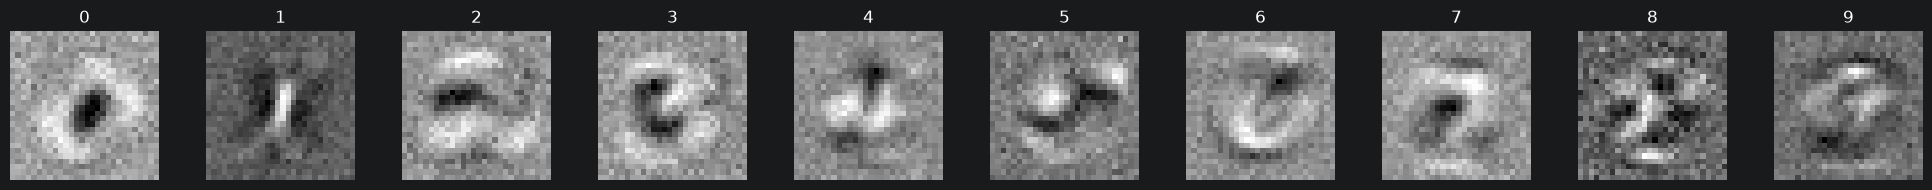

In [24]:
fig, ax = plt.subplots(1, 10, figsize=(20,2))
for i in range(10):
    ax[i].imshow(W[:, i].detach().view(28,28), cmap='gray')
    ax[i].set_title(str(i))
    ax[i].axis('off')
    plt.tight_layout()